# 01 Preprocess: monthly asylum applications in Switzerland

Every forecast starts with the data, so this first notebook prepares the series we want to predict: the monthly number of asylum applications in Switzerland. We load it, check that it is complete and usable, and split the months by time before we look at anything, so that the test period stays unseen until the very end. Then we explore the months before the test period, because what we see there (trends, seasons, the shape of the distribution, the link with the past) tells us which models and features make sense. Finally, we save a clean file for the next notebooks.

We read the raw Eurostat file `../data/raw/eurostat_asylum_ch_monthly.csv` (dataset `migr_asyappctzm`; where it comes from and how it was downloaded is described in `../data/raw/SOURCES.md`). We save the clean data as `../data/processed/asylum_clean.csv`, and three figures in `../output/figures/`.

The notebook must be run with `code/` as the working directory, as explained in the README, because all file paths start from there.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller, acf

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

# adfuller() prints a FutureWarning about its output format; we hide it
warnings.filterwarnings("ignore", category=FutureWarning)

## 1. Load the raw data

We read the CSV file and turn the month column into dates with `pd.to_datetime(..., format="%Y-%m")`. We then use the month as the row label. Working with real dates instead of text lets us select periods, sort by time and plot the series correctly.

Our target is `applicants_total`: all asylum applications in Switzerland in one month, first-time and subsequent applications together, without protection status S. We choose this number because it is exactly the headline figure SEM publishes each month (see `SOURCES.md`), so our forecast speaks the same language as the planners who would use it.

In [2]:
asylum = pd.read_csv("../data/raw/eurostat_asylum_ch_monthly.csv")
asylum["month"] = pd.to_datetime(asylum["month"], format="%Y-%m")
asylum = asylum.set_index("month")

asylum.head()

,applicants_total,applicants_first_time,applicants_subsequent
month,,,
2008-01-01,1050,900,NaN
2008-02-01,860,755,NaN
2008-03-01,880,775,NaN
2008-04-01,1085,975,NaN
2008-05-01,900,815,NaN


## 2. Check the data

A model can only be as good as its data, and some problems would break our method silently. So before we use the data, we check three things.

First, are there missing values? A missing month in the target would leave a hole in every forecast that needs it. Second, is every month between the first and the last one there, without gaps? Our models assume one row per month, so a skipped month would shift everything after it. For monthly data, the number of months must be `12 * (last year - first year) + (last month - first month) + 1`. Third, are all values positive? We need this because we will take the logarithm (section 5), and the logarithm of zero or a negative number does not exist.

In [3]:
print("Number of rows:", asylum.shape[0])
print("First month:", asylum.index[0])
print("Last month: ", asylum.index[-1])
print()
print("Missing values per column:")
print(asylum.isna().sum())

Number of rows: 225
First month: 2008-01-01 00:00:00
Last month:  2026-09-01 00:00:00

Missing values per column:
applicants_total           0
applicants_first_time      0
applicants_subsequent    156
dtype: int64


In [4]:
first, last = asylum.index[0], asylum.index[-1]
n_expected = 12 * (last.year - first.year) + (last.month - first.month) + 1

print("Expected number of months:", n_expected)
print("Number of months in the data:", asylum.shape[0])
print("No gaps:", n_expected == asylum.shape[0])
print("Smallest monthly value of applicants_total:", asylum["applicants_total"].min())

Expected number of months: 225
Number of months in the data: 225
No gaps: True
Smallest monthly value of applicants_total: 330


**What we see.** The file has 225 months, from January 2008 to September 2026. Our target `applicants_total` has no missing values, and neither has `applicants_first_time`. Only `applicants_subsequent` is missing, in 156 months; we do not use this column, so it does not matter. The expected and the actual number of months are both 225, so no month is missing. The smallest value of the target is 330, so all values are positive.

**What this means for us.** The target series is complete and can be used as it is, and we can safely take its logarithm. So we can now split the months by time.

## 3. Split the months by time, before we explore

One rule holds from the first day: we split off the test set **before** we explore, and we do not look at it until the final comparison. If we looked at the test months now, what we saw could influence our choices without us noticing, and the test would no longer be a fair check on unseen months. For data over time, the split must also follow the order of time: we train on earlier months and test on later months, just as a planner can only learn from the past to forecast the future.

We divide the months into three parts:

| Part | Months | Use |
|---|---|---|
| `training` | 2008-01 to 2012-12 | first training window (60 months) |
| `backtest` | 2013-01 to 2024-09 | each month is forecast once by every model, which is trained only on earlier months (expanding window); we choose the model here |
| `test` | 2024-10 to 2026-09 | used once, at the very end |

We start with 60 months of training so that every calendar month appears five times before the first forecast, which is needed to learn the seasonal pattern. The label `training` only marks this first window. In the backtest, the training window then grows by one month at each step, so every model always uses all the months known at the time of its forecast.

In [5]:
BACKTEST_START = pd.Timestamp("2013-01-01")   # first month we forecast in the backtest
TEST_START = pd.Timestamp("2024-10-01")       # first month of the test period

asylum["period"] = "backtest"
asylum.loc[asylum.index < BACKTEST_START, "period"] = "training"
asylum.loc[asylum.index >= TEST_START, "period"] = "test"

print(asylum["period"].value_counts())

period
backtest    141
training     60
test         24
Name: count, dtype: int64


**What we see.** There are 60 months for the first training window, 141 backtest months and 24 test months, together 225 months.

**What this means for us.** Every month of the backtest will be forecast once by every model, so all models will be compared on exactly the same 141 months. Nothing in the comparison can then come from one model being scored on easier months than another.

From here on, we explore **only the months before the test period**, stored in `before_test`, so that nothing we learn about the data comes from the test months.

In [6]:
before_test = asylum.loc[asylum.index < TEST_START].copy()
print("Months used for exploration:", before_test.shape[0])
print("From", before_test.index[0], "to", before_test.index[-1])

Months used for exploration: 201
From 2008-01-01 00:00:00 to 2024-09-01 00:00:00


## 4. Explore the series

### 4.1 The series over time

We start with the simplest question: *how does the number of applications change over time?* Before choosing any model, we need to know whether the series is stable, trending or full of breaks, because that decides what a model must be able to follow. A line plot answers this at a glance. The dashed line marks the start of the backtest.

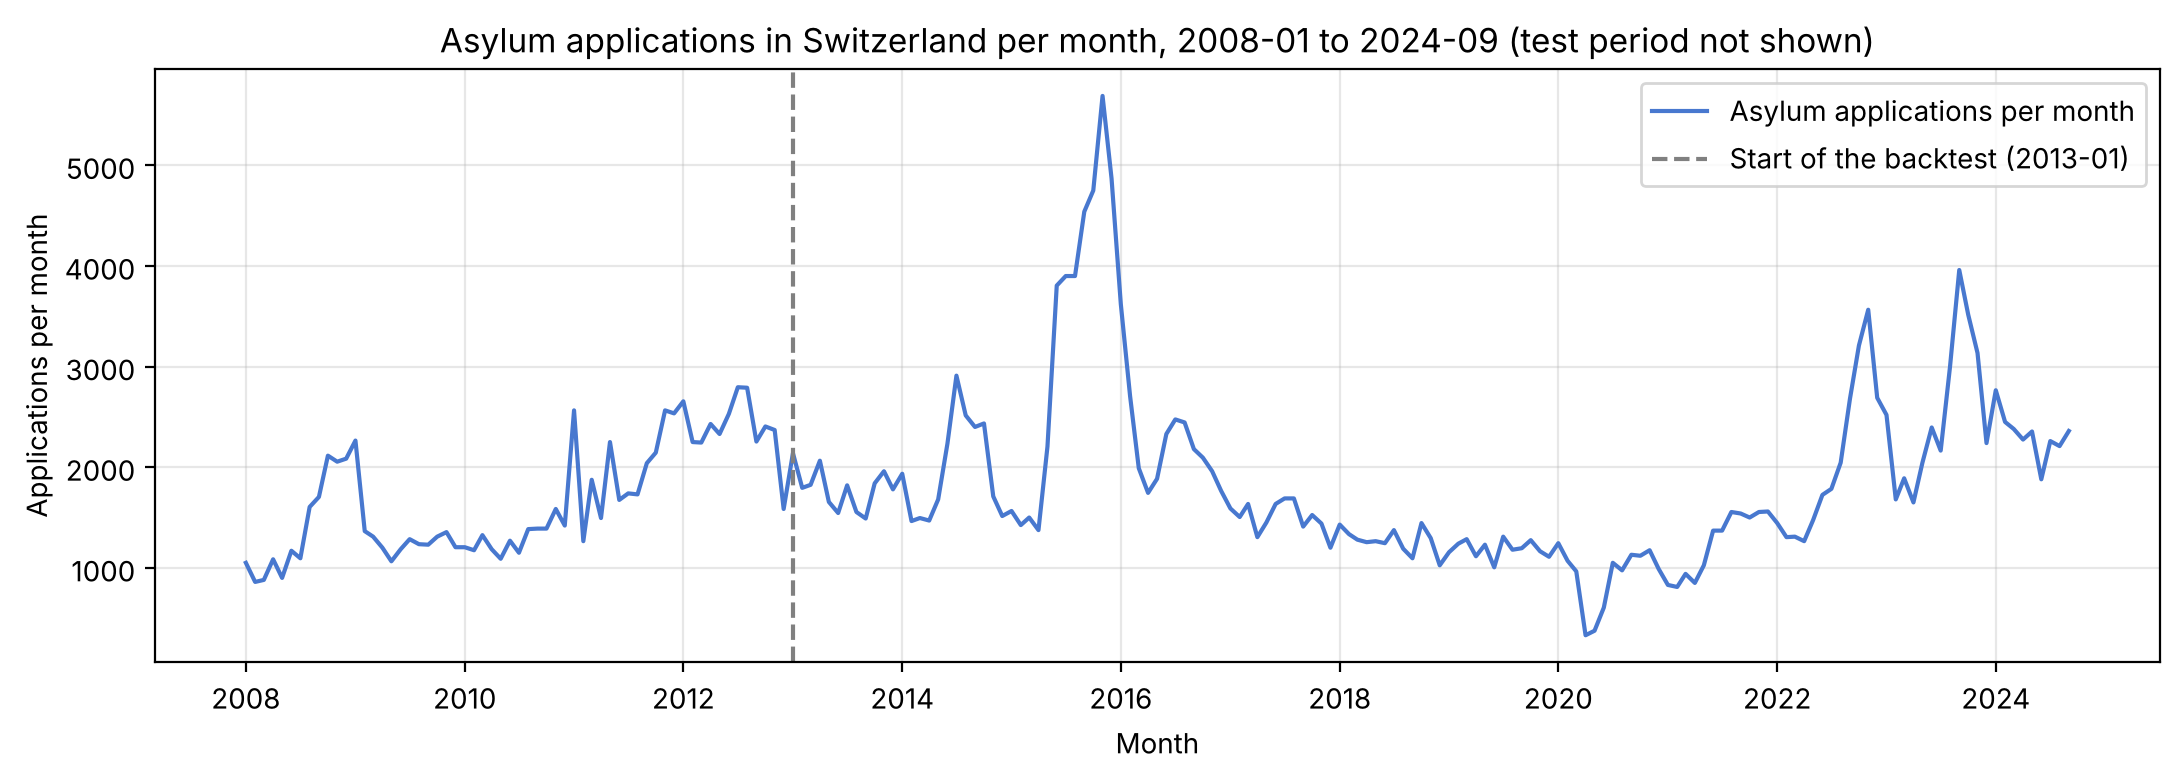

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(before_test.index, before_test["applicants_total"], label="Asylum applications per month")
ax.axvline(BACKTEST_START, color="grey", linestyle="--", label="Start of the backtest (2013-01)")
ax.set_title("Asylum applications in Switzerland per month, 2008-01 to 2024-09 (test period not shown)")
ax.set_xlabel("Month")
ax.set_ylabel("Applications per month")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/01_applications_over_time.png")
plt.show()

In [8]:
# The three highest and the three lowest months (sort_values)
print("Highest months:")
print(before_test["applicants_total"].sort_values(ascending=False).head(3))
print()
print("Lowest months:")
print(before_test["applicants_total"].sort_values().head(3))

Highest months:
month
2015-11-01    5690
2015-12-01    4870
2015-10-01    4750
Name: applicants_total, dtype: int64

Lowest months:
month
2020-04-01    330
2020-05-01    375
2020-06-01    605
Name: applicants_total, dtype: int64


**What we see.** The number of applications is far from constant: it moves between a few hundred and more than 5,000 per month. The three highest months are October to December 2015, with a maximum of 5,690 in November 2015. The three lowest months are April to June 2020, with a minimum of 330 in April 2020. After 2021 the series rises again, with peaks close to 3,500 and 4,000 in the plot.

**What this means for us.** The level changes a lot over time, so a long-run average would often be far off: the most recent months carry the most information about the next ones. That is why we will use the last months (lags) as features. Both the 2015–16 peak and the 2020 drop lie in the backtest, and such exceptional periods can dominate an average error. As planned, we will therefore report the backtest results with and without these periods. Next, we look at whether some months of the year are regularly higher than others.

### 4.2 Seasonality: are some months of the year higher than others?

If applications rise and fall with the seasons, a good forecast must know the calendar. To find out, we compute the average and the median number of applications for each calendar month (January, February, ...) with `groupby`. We show both, because they answer slightly different questions. A few extreme months, such as those of autumn 2015, pull the average up, while the median, the middle value, is much less affected by them (the average belongs to the squared loss, the median to the absolute loss). If both show the same pattern, the pattern does not come from a few extreme months.

*Not seen in class:* `before_test.index.month` gives the calendar month (1 to 12) of each row label.

In [9]:
calendar_month = before_test.index.month   # 1 = January, ..., 12 = December

by_month = before_test.groupby(calendar_month)["applicants_total"].agg(["mean", "median"]).round(0)
by_month.index.name = "calendar month"
by_month

,mean,median
calendar month,,
1,1881.0,1590.0
2,1512.0,1365.0
3,1537.0,1495.0
4,1417.0,1305.0
5,1546.0,1475.0
6,1741.0,1635.0
7,1893.0,1740.0
8,1941.0,1690.0
9,2035.0,1705.0


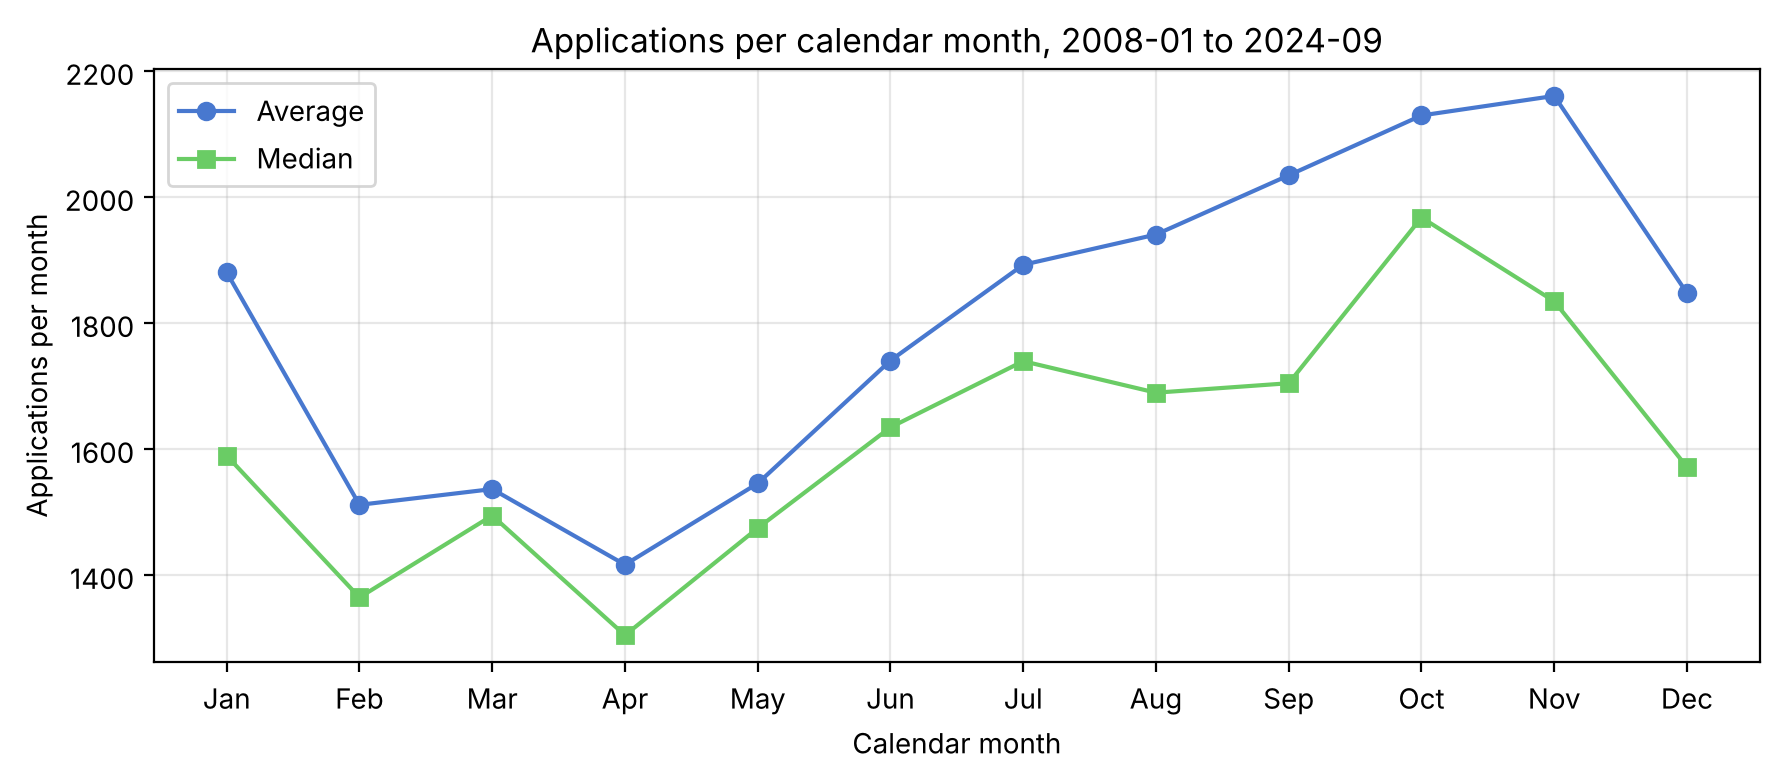

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(by_month.index, by_month["mean"], marker="o", label="Average")
ax.plot(by_month.index, by_month["median"], marker="s", label="Median")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Applications per calendar month, 2008-01 to 2024-09")
ax.set_xlabel("Calendar month")
ax.set_ylabel("Applications per month")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/01_seasonality.png")
plt.show()

**What we see.** Applications are lowest from February to April (lowest median: April, 1,305) and highest in the autumn (highest median: October, 1,968). The median of October is about 50% higher than the median of April. The average is above the median in every calendar month, and the gap is largest in January, September and November: a few very high months pull the average up, such as November 2015 with 5,690 applications (section 4.1). But both lines show the same seasonal shape.

**What this means for us.** There is a clear seasonal pattern within the year, and it is not only due to a few extreme months. This supports two choices: a simple rule that uses the season, the *seasonal naive* baseline (the same month one year earlier), and the value from 12 months earlier (lag 12) as a feature in our models. Before we build them, we look at the distribution of the values.

## 5. Why we model the logarithm of the applications

In a series that moves between a few hundred and several thousand, errors grow with the level: a forecast for a month with 5,000 applications will naturally miss by more than one for a month with 1,000. The logarithm deals with this. It reduces a strong right skew, so that a few very high months do not dominate, and an error in logs is roughly a percentage error (an error of 0.10 is about 10% off). For our problem this fits well: a miss of 200 applications is large in a quiet month with 1,000 applications, but small in a month with 5,000.

To see whether the log really helps, we compare the histograms before and after the logarithm, side by side.

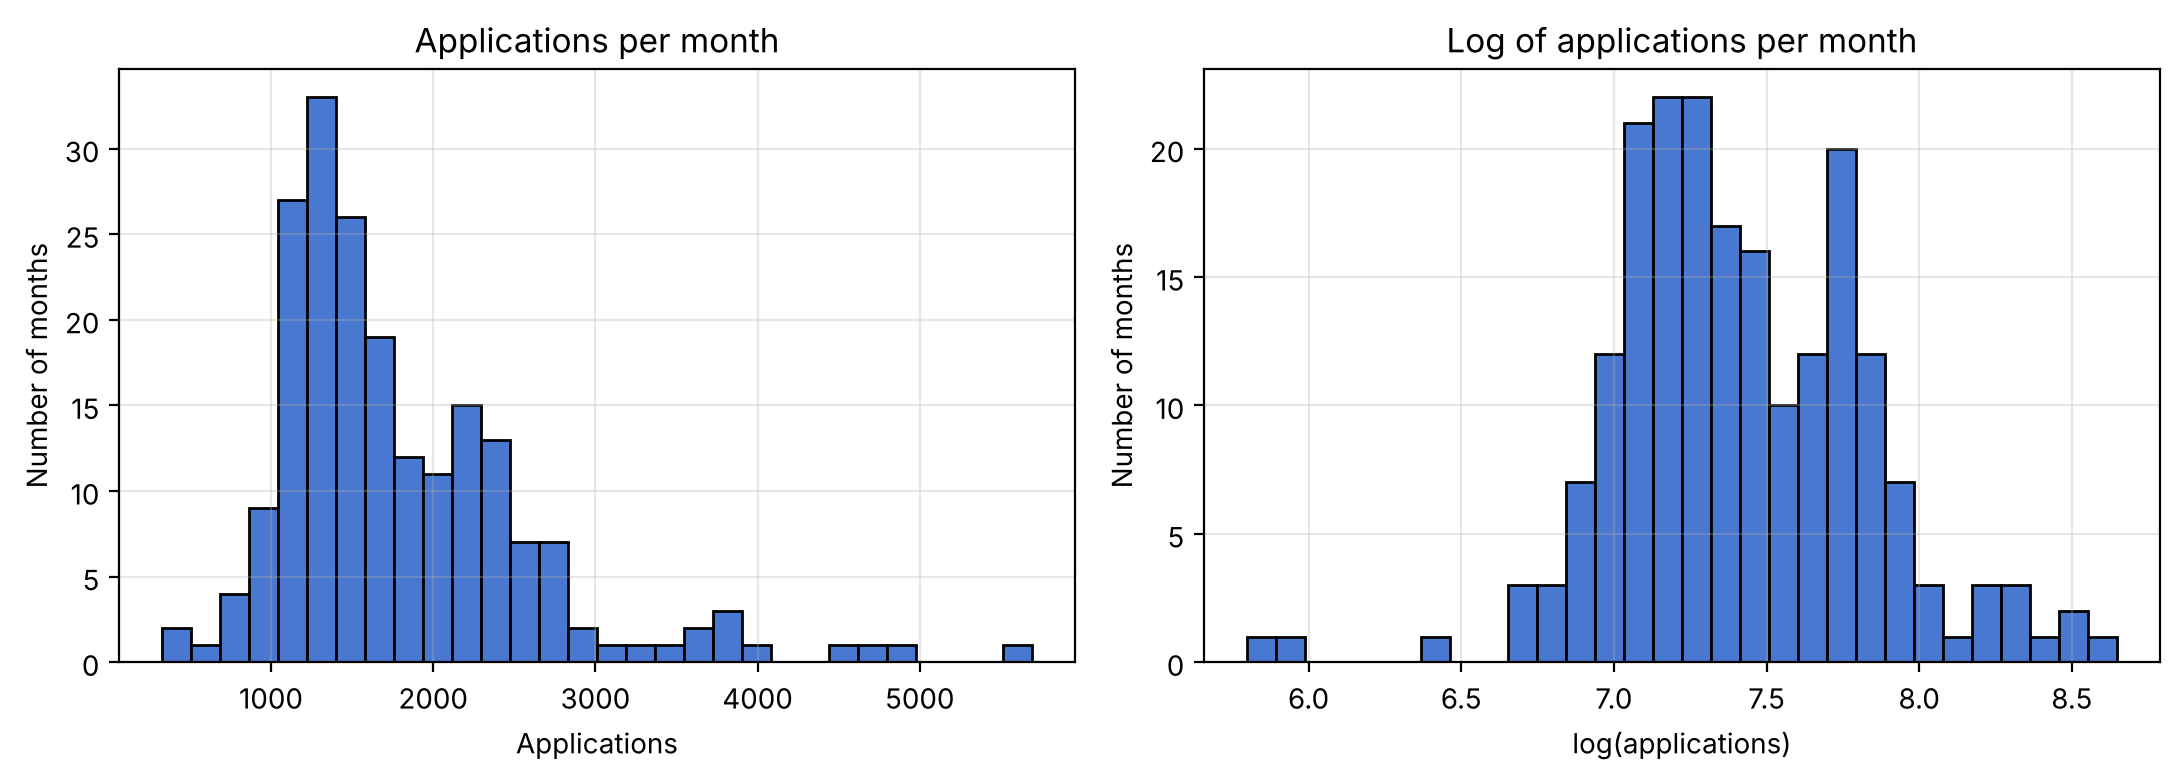

In [11]:
before_test["log_applicants"] = np.log(before_test["applicants_total"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(before_test["applicants_total"], bins=30, edgecolor="black")
axes[0].set_title("Applications per month")
axes[0].set_xlabel("Applications")
axes[0].set_ylabel("Number of months")
axes[1].hist(before_test["log_applicants"], bins=30, edgecolor="black")
axes[1].set_title("Log of applications per month")
axes[1].set_xlabel("log(applications)")
axes[1].set_ylabel("Number of months")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/01_histograms_log.png")
plt.show()

**What we see.** On the left, most months lie between 1,000 and 2,500 applications, with a long tail to the right up to more than 5,000: the distribution is right-skewed. On the right, after the logarithm, the bulk of the months forms a more symmetric shape; only a few months stand apart on the left, below 6.5 (these are the low months of spring 2020: log(330) = 5.8).

**What this means for us.** We model the log of the applications. A planner, however, thinks in applications, so we will transform the forecasts back with `np.exp()` and report our errors in applications per month. Next, we look at how strongly each month depends on the months before it.

## 6. Temporal dependence: the autocorrelation function (ACF)

To forecast from the past, we need to know which past months are linked to the present one. The sample autocorrelation function (ACF) measures this: at lag $k$, it gives the correlation between the series and itself $k$ months earlier. Its shape is informative: it decays geometrically for an AR(1) process, stays high for a random walk, and shows peaks at lags 12, 24, ... when there is monthly seasonality.

We plot the ACF of the log series and of its first difference, $\Delta y_t = y_t - y_{t-1}$ (the change from one month to the next), for lags 0 to 36. We look at both because a series that drifts in level can show high autocorrelations at all lags, which hide the shorter links; the monthly changes show them more clearly.

*Not seen in class:* to read exact values, we also print them with `acf()` from `statsmodels`. It computes the same numbers that `plot_acf()` draws.

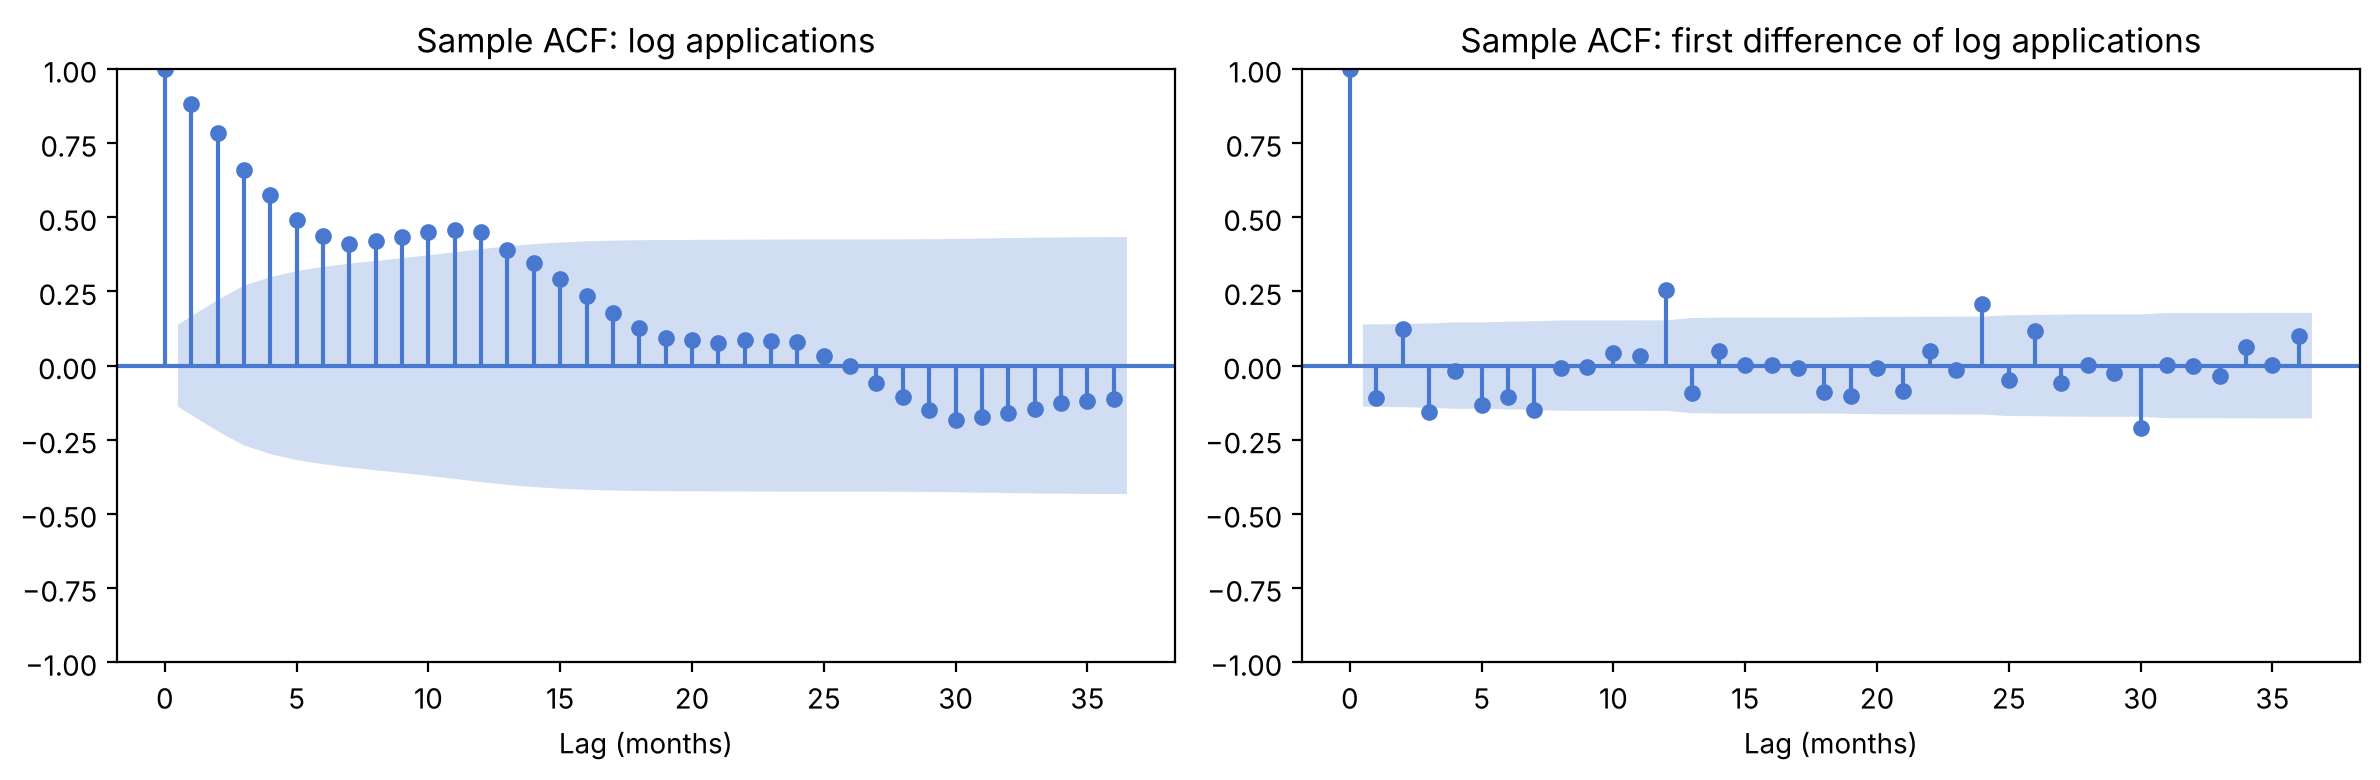

In [12]:
log_y = before_test["log_applicants"]
log_y_diff = np.diff(log_y)   # first difference

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(log_y, lags=36, ax=axes[0])
axes[0].set_title("Sample ACF: log applications")
axes[0].set_xlabel("Lag (months)")
plot_acf(log_y_diff, lags=36, ax=axes[1])
axes[1].set_title("Sample ACF: first difference of log applications")
axes[1].set_xlabel("Lag (months)")
plt.tight_layout()
plt.show()

In [13]:
# The values behind the two plots at a few lags
lags_to_show = [1, 2, 3, 6, 12, 24]
acf_level = acf(log_y, nlags=24)
acf_diff = acf(log_y_diff, nlags=24)
pd.DataFrame({"ACF of log level": acf_level[lags_to_show].round(2),
              "ACF of first difference": acf_diff[lags_to_show].round(2)},
             index=pd.Index(lags_to_show, name="lag"))

,ACF of log level,ACF of first difference
lag,,
1,0.88,-0.11
2,0.78,0.12
3,0.66,-0.16
6,0.44,-0.11
12,0.45,0.25
24,0.08,0.21


**What we see.** On the left (log level), the autocorrelation is high and decreases slowly: 0.88 at lag 1, 0.78 at lag 2, 0.66 at lag 3, with a small bump around lag 12 (0.45). Such persistent autocorrelations are a sign that the series may not be stationary, that is, its level may drift over time, so we read this plot with caution. On the right (first difference), most values lie inside the blue band, which marks values that could arise by chance. The clearest exceptions are lag 12 (0.25) and lag 24 (0.21), the seasonal lags. Lag 30 is also just outside the band; with 36 lags, one value outside the band can happen by chance (sampling variability).

**What this means for us.** Applications depend strongly on the recent past (lags 1 to 3) and on the same month one year earlier (lag 12). These are the lags we will use in our models. The ACF only suggests candidate models, though; we choose between them on their forecasts in the backtest. First, we check more formally whether the series is stationary.

## 7. Stationarity: the Augmented Dickey-Fuller (ADF) test

The ACF suggested that the level of the series may drift. This matters for the choice of model: ARIMA-type models need a stationary series, and if the series is not stationary, we must model its changes instead of its level. The Augmented Dickey-Fuller (ADF) test checks this. Its null hypothesis is that the series has a unit root, meaning it is not stationary; a small p-value (below 0.05) rejects the unit root. We use `adfuller()` with a constant (`regression="c"`), because the series moves around a non-zero level, and with `autolag="AIC"`, which chooses the number of past changes in the test automatically. We test both the log series and its first difference.

In [14]:
for name, series in [("log applications", log_y), ("first difference of log applications", log_y_diff)]:
    result = adfuller(series, regression="c", autolag="AIC")
    statistic, pvalue = result[0], result[1]
    decision = "reject the unit root at 5%" if pvalue < 0.05 else "do not reject the unit root at 5%"
    print(f"{name:40s} ADF statistic {statistic:7.3f}   p-value {pvalue:.4f}   -> {decision}")

log applications                         ADF statistic  -2.023   p-value 0.2766   -> do not reject the unit root at 5%
first difference of log applications     ADF statistic  -8.047   p-value 0.0000   -> reject the unit root at 5%


**What we see.** For the log series, the p-value is 0.2766, so we cannot reject the unit root at 5%. For its first difference, the p-value is 0.0000, so we reject the unit root.

**What this means for us.** The log series behaves like a non-stationary series, while its monthly changes look stationary. For the SARIMA candidates, this suggests one difference (d = 1), and for our regressions, it suggests predicting changes rather than levels. A test result is not a proof, though: breaks such as 2015–16 and 2020 can affect the test. So we also compare candidates directly on their forecasts in the backtest instead of relying on the test alone.

## 8. Save the clean data

We keep only what the next notebooks need: the month, the target in applications, its logarithm and the period label. The log is computed for all 225 months, including the test months. This does not leak anything from the test period, because the logarithm only transforms each value on its own: nothing is learned from other months. The next notebook reads this file.

In [15]:
asylum["log_applicants"] = np.log(asylum["applicants_total"])

clean = asylum[["applicants_total", "log_applicants", "period"]].reset_index()
clean.to_csv("../data/processed/asylum_clean.csv", index=False)

print("Saved", clean.shape[0], "months and the columns", list(clean.columns))

Saved 225 months and the columns ['month', 'applicants_total', 'log_applicants', 'period']


## Summary

**The data are complete.** We have 225 months, from January 2008 to September 2026, without missing values or gaps in the target, and all values are positive, so we can take the logarithm.

**The test period stays unseen.** We split the months by time before exploring: 60 months for the first training window, 141 backtest months and 24 test months. We explored only the 201 months before the test period.

**Four findings guide the models.** First, the level changes a lot over time, so the recent months matter most (lags 1 to 3). Second, there is a seasonal pattern, with low months in spring and high months in autumn, which supports the seasonal naive baseline and the lag 12 as a feature. Third, the distribution is right-skewed, so we model the log and report errors in applications per month. Fourth, the log series looks non-stationary and its first difference stationary, so we model changes (d = 1 for the SARIMA candidates).

The clean file `../data/processed/asylum_clean.csv` is used by `02_estimate.ipynb`.